<a href="https://www.kaggle.com/code/arafat1746/document-image-enhancement-for-ocr?scriptVersionId=320200433" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

<div style="background: linear-gradient(135deg, #eef6ff 0%, #f7ecff 50%, #eafff5 100%); padding: 28px; border-radius: 18px; border: 1px solid #d8e6ff; font-family: Arial, sans-serif; color: #1f2937;">

<h1 style="color:#1d4ed8; text-align:center; margin-bottom: 10px;">
📄 Image Preprocessing for OCR
</h1>

<hr style="border: none; height: 3px; background: linear-gradient(90deg, #2563eb, #9333ea, #10b981); border-radius: 10px; margin: 20px 0;">

<h2 style="color:#7c3aed;">
✨ Main Steps Used
</h2>

<div style="background:#ffffffcc; padding:18px; border-radius:14px; border-left:6px solid #2563eb; margin-bottom:14px;">
<h3 style="color:#2563eb; margin-top:0;">1. Grayscale Conversion</h3>
<p>Converts RGB image into intensity image.</p>
</div>

<div style="background:#ffffffcc; padding:18px; border-radius:14px; border-left:6px solid #10b981; margin-bottom:14px;">
<h3 style="color:#059669; margin-top:0;">2. Median Filter</h3>
<p>Removes small noise while preserving text edges.</p>
</div>

<div style="background:#ffffffcc; padding:18px; border-radius:14px; border-left:6px solid #f59e0b; margin-bottom:14px;">
<h3 style="color:#d97706; margin-top:0;">3. Adaptive Thresholding</h3>
<p>Separates text from background under uneven lighting.</p>
</div>

<div style="background:#ffffffcc; padding:18px; border-radius:14px; border-left:6px solid #ec4899; margin-bottom:20px;">
<h3 style="color:#db2777; margin-top:0;">4. Morphological Cleaning</h3>
<p>Removes small noise and improves text structure.</p>
</div>

<h2 style="color:#0891b2;">
🎯 Objective
</h2>

<div style="background:#f0fdfa; padding:18px; border-radius:14px; border:1px solid #99f6e4;">
<p style="font-size:16px; line-height:1.7; margin:0;">
The goal is to show clear visual difference between the original input image and the processed OCR-ready output image.
</p>
</div>

</div>

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["image.cmap"] = "gray"

print("OpenCV version:", cv2.__version__)

OpenCV version: 4.12.0


<div style="background: linear-gradient(135deg, #fff7ed 0%, #eff6ff 50%, #f0fdf4 100%); padding: 24px; border-radius: 18px; border: 1px solid #dbeafe; font-family: Arial, sans-serif; color: #1f2937;">

<h2 style="color:#2563eb; margin-top:0;">
📁 Input and Output Path
</h2>

<div style="background:#ffffffcc; padding:18px; border-radius:14px; border-left:6px solid #f97316; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
Here, we define the input image path and output directory.
</p>

<p style="font-size:16px; line-height:1.7; margin:0;">
The processed images will be saved in the output folder.
</p>

</div>

</div>

In [2]:
IMAGE_PATH = "/kaggle/input/datasets/arafat1746/arafat52/3.jpeg"
OUTPUT_DIR = "/kaggle/working/output"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Input image path:", IMAGE_PATH)
print("Output folder:", OUTPUT_DIR)

Input image path: /kaggle/input/datasets/arafat1746/arafat52/3.jpeg
Output folder: /kaggle/working/output


<div style="background: linear-gradient(135deg, #fdf2f8 0%, #eef2ff 50%, #ecfeff 100%); padding: 24px; border-radius: 18px; border: 1px solid #c7d2fe; font-family: Arial, sans-serif; color: #1f2937;">

<h2 style="color:#7c3aed; margin-top:0;">
🖼️ Helper Functions
</h2>

<div style="background:#ffffffcc; padding:18px; border-radius:14px; border-left:6px solid #7c3aed; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 14px 0;">
These functions are used to display images clearly in the notebook.
</p>

<ul style="font-size:16px; line-height:1.8; margin:0; padding-left:22px;">
<li><code style="background:#f3e8ff; color:#6d28d9; padding:3px 7px; border-radius:6px;">show_image()</code> displays a single image.</li>
<li><code style="background:#e0f2fe; color:#0369a1; padding:3px 7px; border-radius:6px;">show_grid()</code> displays multiple images in one comparison view.</li>
</ul>

</div>

</div>

In [3]:
def show_image(title, img, cmap="gray", figsize=(7, 6)):
    plt.figure(figsize=figsize)

    if len(img.shape) == 2:
        plt.imshow(img, cmap=cmap)
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    plt.title(title, fontsize=14, fontweight="bold")
    plt.axis("off")
    plt.show()


def show_grid(images, cols=2, figsize=(14, 10)):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=figsize)

    for i, (title, img) in enumerate(images, 1):
        plt.subplot(rows, cols, i)

        if len(img.shape) == 2:
            plt.imshow(img, cmap="gray")
        else:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

        plt.title(title, fontsize=12, fontweight="bold")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

<div style="background: linear-gradient(135deg, #f0fdf4 0%, #ecfeff 50%, #fefce8 100%); padding: 24px; border-radius: 18px; border: 1px solid #bbf7d0; font-family: Arial, sans-serif; color: #1f2937;">

<h2 style="color:#16a34a; margin-top:0;">
🟩 Step 1: Load Original Image
</h2>

<div style="background:#ffffffcc; padding:18px; border-radius:14px; border-left:6px solid #22c55e; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
The input document image is loaded using OpenCV.
</p>

<p style="font-size:16px; line-height:1.7; margin:0;">
This image may contain noise, uneven lighting, or low contrast, so preprocessing is required before OCR.
</p>

</div>

</div>

Image shape: (1150, 871, 3)


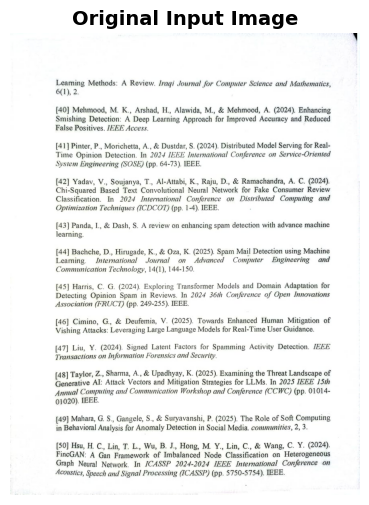

In [4]:
img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

print("Image shape:", img.shape)

show_image("Original Input Image", img, cmap=None)

<div style="background: linear-gradient(135deg, #fefce8 0%, #fff7ed 50%, #eff6ff 100%); padding: 24px; border-radius: 18px; border: 1px solid #fde68a; font-family: Arial, sans-serif; color: #1f2937;">

<h2 style="color:#ca8a04; margin-top:0;">
🟨 Step 2: Grayscale Conversion
</h2>

<div style="background:#ffffffcc; padding:18px; border-radius:14px; border-left:6px solid #eab308; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 14px 0;">
Grayscale conversion is the first important preprocessing step.
</p>

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
A color image has three channels: <strong style="color:#dc2626;">Red</strong>, 
<strong style="color:#16a34a;">Green</strong>, and 
<strong style="color:#2563eb;">Blue</strong>.
</p>

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
For OCR preprocessing, color information is usually not necessary.
</p>

<p style="font-size:16px; line-height:1.7; margin:0;">
Therefore, the image is converted into a single-channel intensity image.
</p>

</div>

<div style="background:#fffbeb; padding:18px; border-radius:14px; border:1px solid #facc15; margin-top:18px; box-shadow: 0 6px 18px rgba(0,0,0,0.06);">

<h3 style="color:#b45309; margin-top:0;">
📌 DIP Concept
</h3>

<p style="font-size:16px; line-height:1.7; margin:0;">
Grayscale conversion reduces computational complexity and keeps only intensity information.
</p>

</div>

</div>

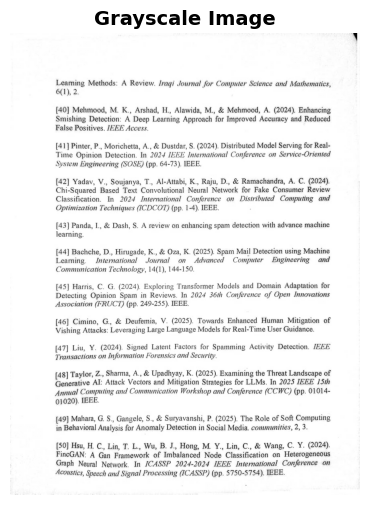

In [5]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

show_image("Grayscale Image", gray)

<div style="background: linear-gradient(135deg, #fefce8 0%, #fff7ed 48%, #eff6ff 100%); padding: 26px; border-radius: 20px; border: 1px solid #fde68a; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#ca8a04; margin-top:0; margin-bottom:16px;">
🟨 Step 2: Grayscale Conversion
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #eab308; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 14px 0;">
Grayscale conversion is the first important preprocessing step.
</p>

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
A color image has three channels: 
<strong style="color:#dc2626;">Red</strong>, 
<strong style="color:#16a34a;">Green</strong>, and 
<strong style="color:#2563eb;">Blue</strong>.
</p>

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
For OCR preprocessing, color information is usually not necessary.
</p>

<p style="font-size:16px; line-height:1.7; margin:0;">
Therefore, the image is converted into a single-channel intensity image.
</p>

</div>

<div style="background: linear-gradient(135deg, #fffbeb 0%, #fef3c7 100%); padding:18px; border-radius:15px; border:1px solid #facc15; margin-top:18px; box-shadow: 0 6px 18px rgba(0,0,0,0.06);">

<h3 style="color:#b45309; margin-top:0; margin-bottom:10px;">
📌 DIP Concept
</h3>

<p style="font-size:16px; line-height:1.7; margin:0;">
Grayscale conversion reduces computational complexity and keeps only intensity information.
</p>

</div>

</div>

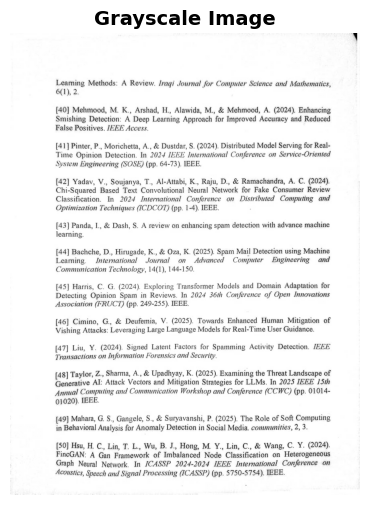

In [6]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

show_image("Grayscale Image", gray)

<div style="background: linear-gradient(135deg, #fff7ed 0%, #ffedd5 45%, #fefce8 100%); padding: 26px; border-radius: 20px; border: 1px solid #fed7aa; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#ea580c; margin-top:0; margin-bottom:16px;">
🟧 Step 3: Median Filter for Noise Removal
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #f97316; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 14px 0;">
The median filter is a <strong style="color:#c2410c;">non-linear spatial filter</strong>.
</p>

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
It replaces each pixel value with the median value of its neighboring pixels.
</p>

<p style="font-size:16px; line-height:1.7; margin:0;">
This is useful for removing small noise while preserving text edges.
</p>

</div>

<div style="background: linear-gradient(135deg, #fff7ed 0%, #fed7aa 100%); padding:18px; border-radius:15px; border:1px solid #fb923c; margin-top:18px; box-shadow: 0 6px 18px rgba(0,0,0,0.06);">

<h3 style="color:#c2410c; margin-top:0; margin-bottom:12px;">
📌 Why Median Filter?
</h3>

<ul style="font-size:16px; line-height:1.8; margin:0; padding-left:22px;">
<li>Removes salt-and-pepper noise</li>
<li>Preserves edges better than simple averaging</li>
<li>Helps OCR by making text cleaner</li>
</ul>

</div>

</div>

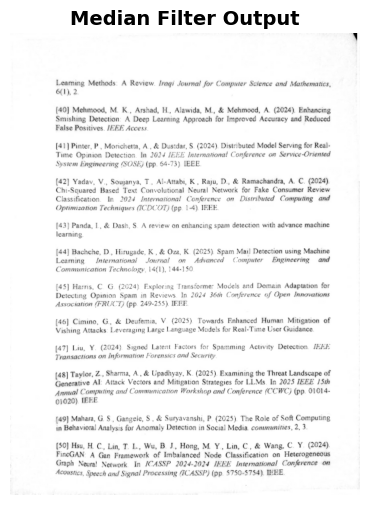

In [7]:
median = cv2.medianBlur(gray, 3)

show_image("Median Filter Output", median)

<div style="background: linear-gradient(135deg, #fef2f2 0%, #fff7ed 48%, #fefce8 100%); padding: 26px; border-radius: 20px; border: 1px solid #fecaca; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#dc2626; margin-top:0; margin-bottom:16px;">
🟥 Step 4: Adaptive Thresholding
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #ef4444; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 14px 0;">
Thresholding converts a grayscale image into a binary image.
</p>

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
In a binary image:
</p>

<ul style="font-size:16px; line-height:1.8; margin:0 0 14px 0; padding-left:22px;">
<li>Text becomes black or white</li>
<li>Background becomes the opposite color</li>
</ul>

<p style="font-size:16px; line-height:1.7; margin:0;">
Adaptive thresholding is better than simple global thresholding when the image has uneven lighting.
</p>

</div>

<div style="background: linear-gradient(135deg, #fee2e2 0%, #ffedd5 100%); padding:18px; border-radius:15px; border:1px solid #f87171; margin-top:18px; box-shadow: 0 6px 18px rgba(0,0,0,0.06);">


<p style="font-size:16px; line-height:1.7; margin:0;">
Adaptive thresholding calculates a local threshold for small regions of the image instead of using one fixed threshold for the whole image.
</p>

</div>

</div>

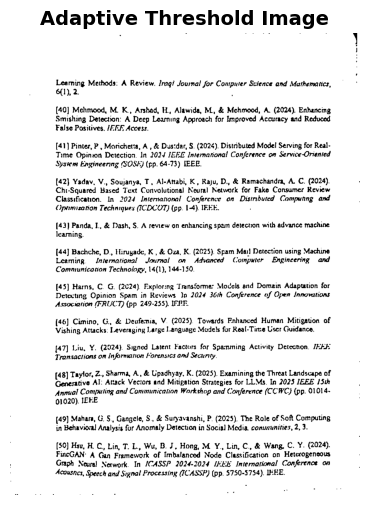

In [8]:
adaptive_thresh = cv2.adaptiveThreshold(
    median,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

show_image("Adaptive Threshold Image", adaptive_thresh)

<div style="background: linear-gradient(135deg, #faf5ff 0%, #eef2ff 48%, #fdf2f8 100%); padding: 26px; border-radius: 20px; border: 1px solid #ddd6fe; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#7c3aed; margin-top:0; margin-bottom:16px;">
🟪 Step 5: Morphological Cleaning
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #8b5cf6; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 14px 0;">
Morphological operations are used to improve the binary image.
</p>

<p style="font-size:16px; line-height:1.7; margin:0;">
Here, <strong style="color:#7c3aed;">morphological closing</strong> is used.
</p>

</div>

<div style="background: linear-gradient(135deg, #f3e8ff 0%, #ede9fe 100%); padding:18px; border-radius:15px; border:1px solid #c4b5fd; margin-top:18px; box-shadow: 0 6px 18px rgba(0,0,0,0.06);">

<h3 style="color:#6d28d9; margin-top:0; margin-bottom:10px;">
📌 Closing Operation
</h3>

<p style="font-size:16px; line-height:1.7; margin:0 0 12px 0;">
Closing = Dilation followed by Erosion
</p>

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
It helps to:
</p>

<ul style="font-size:16px; line-height:1.8; margin:0; padding-left:22px;">
<li>Connect broken text strokes</li>
<li>Fill small gaps inside characters</li>
<li>Improve OCR readability</li>
</ul>

</div>

</div>

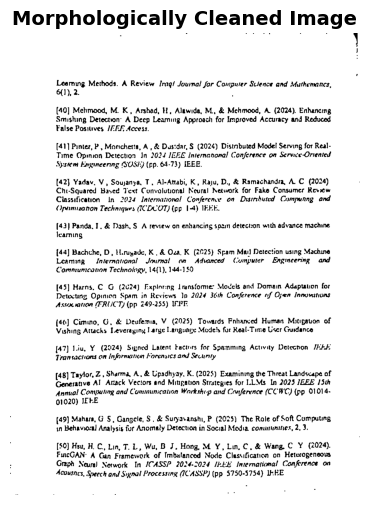

In [9]:
kernel = np.ones((2, 2), np.uint8)

clean = cv2.morphologyEx(
    adaptive_thresh,
    cv2.MORPH_CLOSE,
    kernel,
    iterations=1
)

show_image("Morphologically Cleaned Image", clean)

<div style="background: linear-gradient(135deg, #ecfeff 0%, #eff6ff 48%, #f0fdf4 100%); padding: 26px; border-radius: 20px; border: 1px solid #bae6fd; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#0891b2; margin-top:0; margin-bottom:16px;">
🔍 Final Visual Comparison
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #06b6d4; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 12px 0;">
This section shows the visual difference between the input image and each processed output image.
</p>

<p style="font-size:16px; line-height:1.7; margin:0;">
The main objective is to demonstrate how DIP preprocessing changes and improves the image before OCR.
</p>

</div>

</div>

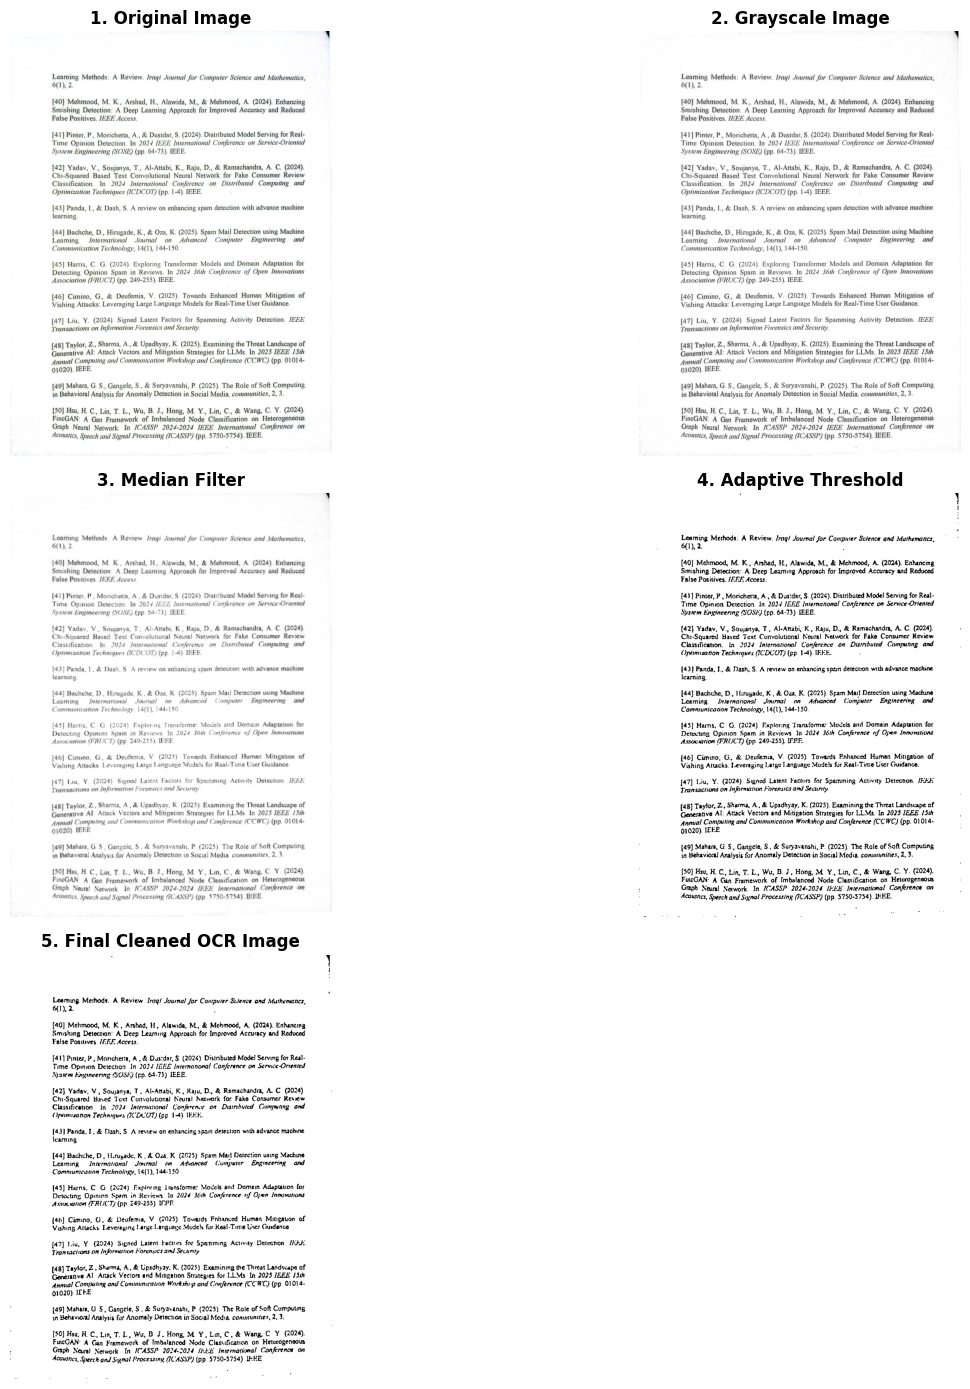

In [10]:
comparison_images = [
    ("1. Original Image", img),
    ("2. Grayscale Image", gray),
    ("3. Median Filter", median),
    ("4. Adaptive Threshold", adaptive_thresh),
    ("5. Final Cleaned OCR Image", clean),
]

show_grid(comparison_images, cols=2, figsize=(14, 14))

<div style="background: linear-gradient(135deg, #f0fdf4 0%, #ecfeff 48%, #eff6ff 100%); padding: 26px; border-radius: 20px; border: 1px solid #bbf7d0; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#16a34a; margin-top:0; margin-bottom:16px;">
💾 Save Output Images
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #22c55e; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 12px 0;">
All important processed images are saved in the output directory.
</p>

<p style="font-size:16px; line-height:1.7; margin:0;">
These saved images can be used in project reports or presentations.
</p>

</div>

</div>

In [11]:
cv2.imwrite(os.path.join(OUTPUT_DIR, "01_grayscale.png"), gray)
cv2.imwrite(os.path.join(OUTPUT_DIR, "02_median_filter.png"), median)
cv2.imwrite(os.path.join(OUTPUT_DIR, "03_adaptive_threshold.png"), adaptive_thresh)
cv2.imwrite(os.path.join(OUTPUT_DIR, "04_final_cleaned_ocr_image.png"), clean)

print("Saved output files:")
for file in os.listdir(OUTPUT_DIR):
    print(file)

Saved output files:
03_adaptive_threshold.png
01_grayscale.png
02_median_filter.png
04_final_cleaned_ocr_image.png


<div style="background: linear-gradient(135deg, #f0fdf4 0%, #ecfeff 48%, #fefce8 100%); padding: 26px; border-radius: 20px; border: 1px solid #86efac; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#15803d; margin-top:0; margin-bottom:16px;">
✅ Final OCR Input Image
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #22c55e; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0 0 14px 0;">
This is the final preprocessed image that can be passed to an OCR engine.
</p>

<p style="font-size:16px; line-height:1.7; margin:0 0 10px 0;">
The image is now:
</p>

<ul style="font-size:16px; line-height:1.8; margin:0; padding-left:22px;">
<li>Grayscale processed</li>
<li>Noise reduced</li>
<li>Converted to binary</li>
<li>Cleaned using morphology</li>
</ul>

</div>

</div>

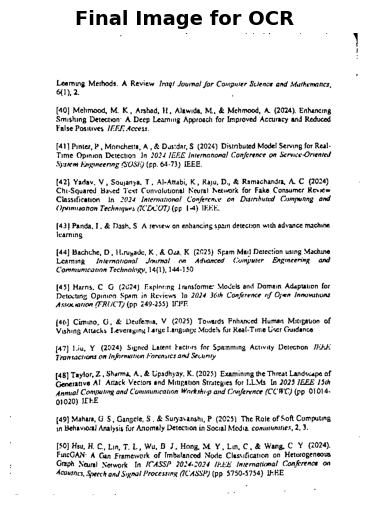

In [12]:
final_for_ocr = clean

show_image("Final Image for OCR", final_for_ocr)

<div style="background: linear-gradient(135deg, #eff6ff 0%, #f5f3ff 48%, #ecfdf5 100%); padding: 26px; border-radius: 20px; border: 1px solid #bfdbfe; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#2563eb; margin-top:0; margin-bottom:16px;">
⚙️ Full Pipeline Function
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #3b82f6; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0;">
This function combines all preprocessing steps into one reusable function.
</p>

</div>

<div style="background: linear-gradient(135deg, #dbeafe 0%, #ede9fe 55%, #dcfce7 100%); padding:18px; border-radius:15px; border:1px solid #93c5fd; margin-top:18px; box-shadow: 0 6px 18px rgba(0,0,0,0.06);">

<h3 style="color:#1d4ed8; margin-top:0; margin-bottom:12px;">
📌 Pipeline
</h3>

<div style="font-size:16px; line-height:2; margin:0; color:#1f2937;">

<span style="background:#ffffffcc; padding:6px 10px; border-radius:8px; color:#2563eb; font-weight:bold;">Input Image</span>
<br>
<span style="color:#64748b; font-weight:bold;">→</span>
<span style="background:#fef9c3; padding:6px 10px; border-radius:8px; color:#ca8a04; font-weight:bold;">Grayscale Conversion</span>
<br>
<span style="color:#64748b; font-weight:bold;">→</span>
<span style="background:#ffedd5; padding:6px 10px; border-radius:8px; color:#ea580c; font-weight:bold;">Median Filtering</span>
<br>
<span style="color:#64748b; font-weight:bold;">→</span>
<span style="background:#fee2e2; padding:6px 10px; border-radius:8px; color:#dc2626; font-weight:bold;">Adaptive Thresholding</span>
<br>
<span style="color:#64748b; font-weight:bold;">→</span>
<span style="background:#f3e8ff; padding:6px 10px; border-radius:8px; color:#7c3aed; font-weight:bold;">Morphological Cleaning</span>
<br>
<span style="color:#64748b; font-weight:bold;">→</span>
<span style="background:#dcfce7; padding:6px 10px; border-radius:8px; color:#16a34a; font-weight:bold;">OCR-ready Output Image</span>

</div>

</div>

</div>

In [13]:
def balanced_dip_ocr_preprocessing(image_path):
    """
     preprocessing pipeline for OCR.

    Steps:
    1. Load image
    2. Convert to grayscale
    3. Apply median filter
    4. Apply adaptive thresholding
    5. Apply morphological closing
    6. Return final OCR-ready image
    """

    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(f"Image not found: {image_path}")

    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    median_image = cv2.medianBlur(gray_image, 3)

    threshold_image = cv2.adaptiveThreshold(
        median_image,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31,
        11
    )

    kernel = np.ones((2, 2), np.uint8)

    cleaned_image = cv2.morphologyEx(
        threshold_image,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=1
    )

    return cleaned_image

<div style="background: linear-gradient(135deg, #eef2ff 0%, #ecfeff 48%, #f0fdf4 100%); padding: 26px; border-radius: 20px; border: 1px solid #c7d2fe; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#4f46e5; margin-top:0; margin-bottom:16px;">
🚀 Run the Full Pipeline
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #6366f1; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0;">
The full preprocessing function is applied to the input document image.
</p>

</div>

</div>

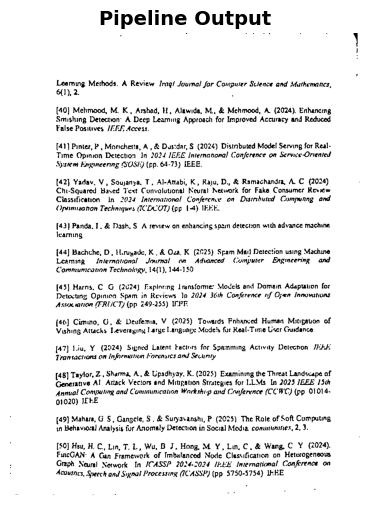

Pipeline completed successfully.


In [14]:
result = balanced_dip_ocr_preprocessing(IMAGE_PATH)

show_image("Pipeline Output", result)

cv2.imwrite(os.path.join(OUTPUT_DIR, "05_pipeline_output.png"), result)

print("Pipeline completed successfully.")

<div style="background: linear-gradient(135deg, #fdf2f8 0%, #eef2ff 48%, #ecfeff 100%); padding: 26px; border-radius: 20px; border: 1px solid #fbcfe8; font-family: Arial, sans-serif; color: #1f2937; box-shadow: 0 8px 24px rgba(0,0,0,0.07);">

<h2 style="color:#db2777; margin-top:0; margin-bottom:16px;">
🔠  OCR Text Extraction
</h2>

<div style="background:#ffffffd9; padding:18px; border-radius:15px; border-left:7px solid #ec4899; box-shadow: 0 6px 18px rgba(0,0,0,0.08);">

<p style="font-size:16px; line-height:1.7; margin:0;">
This cell uses Tesseract OCR to extract text from the final preprocessed image.
</p>

</div>

</div>

In [15]:
try:
    import pytesseract

    extracted_text = pytesseract.image_to_string(result, lang="eng", config="--oem 3 --psm 6")

    print("Extracted OCR Text:")
    print("-" * 60)
    print(extracted_text)

except Exception as e:
    print("OCR could not be completed in this environment.")
    print("Reason:", e)

Extracted OCR Text:
------------------------------------------------------------
1
Leaming Methods. A Review Inig/ Jounal for Computer Stience and Mathematics,
(1), 2. .
(40] Mehmood, M. K, Arshad, H, Alawida, M, & Mchmood, A. (2024). Enhancing
Smishing Detection’ A Deep Learning Approach for Improved Accuracy and Reduced
False Posiuves [EAL Access.
[41] Pintez, P,, Morichetta, A, & Dus:dar, § (2024) Distnbuted Model Serving for Real-
Time Opinion Detection In 2624 JEEE Intemanonal Conference on Service-Onented
System Engineering GOSH) (pp. 64-73) IEEE.
[42] Yadav. V, Soujanya, T, Al-Attabi, K, Raju, D., & Ramachandia, A. C (2024)
Chi-Squared Based Text Convolutional Neural Network for Fake Consumer Rewew
Classification In 2024 International Conference on Disirihuted Compunng and
Opamuanon Techniques GCDCOT) (ep 1-4) IEEE.
(43) Panda. 1, & Dash, § A review on enhancing spain detect:on with advance machine
learning
[44] Bachche, D, Hanuyade, K, & Oza, K (2025) Spam Mail Detection using 